# 2. Zusätzliche Hinweise für die Vorhersage

Welche Informationen könnten über Geschlecht, Alter und Ticketklasse hinaus helfen? Wir erstellen zehn Gruppen von Merkmalen und beschreiben die dahinterliegenden Ideen.

Die folgenden Auswertungen verwenden alle 891 Personen mit bekanntem Überleben. Erst [Notebook 3](03_Modellvergleich.ipynb) prüft, ob diese Hinweise bessere Vorhersagen ermöglichen.


In [1]:
# Gestaltung der Abbildungen.
import json
from pathlib import Path
import matplotlib as mpl
import matplotlib.pyplot as plt
from cycler import cycler
from matplotlib import font_manager as fm
from matplotlib.lines import Line2D
from matplotlib.colors import LinearSegmentedColormap, to_rgb
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
COLORS = {'dk2': '#732124', 'lt2': '#F0EDE5', 'accent1': '#D34817', 'accent2': '#A68D65', 'accent3': '#728377', 'accent4': '#B4797B', 'accent5': '#CE8439', 'accent6': '#CF3A2A', 'hlink': '#D06853', 'folHlink': '#B67779'}
MAJOR_FONTS = ('Rockwell Nova Light', 'Rockwell Nova', 'Rockwell', 'DejaVu Serif')
MINOR_FONTS = ('Avenir Next LT Pro Light', 'Avenir Next LT Pro', 'Avenir Next', 'Calibri Light', 'Calibri', 'DejaVu Sans')
LEAF_CMAP = LinearSegmentedColormap.from_list('leaf', [COLORS['lt2'], COLORS['accent4'], COLORS['dk2']])
LEAF_CMAP.set_bad(COLORS['lt2'])

def heatmap_text_color(value, vmin=0, vmax=1):
    background = LEAF_CMAP((value - vmin) / (vmax - vmin))[:3]

    def luminance(rgb):
        linear = [v / 12.92 if v <= 0.04045 else ((v + 0.055) / 1.055) ** 2.4 for v in rgb]
        return sum((v * w for v, w in zip(linear, [0.2126, 0.7152, 0.0722])))
    luminance_background = luminance(background)

    def contrast(color):
        light = luminance(to_rgb(color))
        return (max(light, luminance_background) + 0.05) / (min(light, luminance_background) + 0.05)
    return max((COLORS['dk2'], COLORS['lt2']), key=contrast)

def resolved_fonts():
    available = {font.name for font in fm.fontManager.ttflist}
    major = next((name for name in MAJOR_FONTS if name in available))
    minor = next((name for name in MINOR_FONTS if name in available))
    return {'requested_heading': MAJOR_FONTS[0], 'heading': major, 'requested_body': MINOR_FONTS[0], 'body': minor, 'heading_file': fm.findfont(fm.FontProperties(family=major)), 'body_file': fm.findfont(fm.FontProperties(family=minor))}

def apply_leaf_theme():
    fonts = resolved_fonts()
    mpl.rcParams.update({'font.family': fonts['body'], 'font.size': 11, 'font.weight': 'normal', 'text.color': COLORS['dk2'], 'figure.facecolor': COLORS['lt2'], 'axes.facecolor': COLORS['lt2'], 'savefig.facecolor': COLORS['lt2'], 'savefig.transparent': False, 'axes.edgecolor': COLORS['accent2'], 'axes.linewidth': 0.7, 'axes.labelcolor': COLORS['dk2'], 'axes.labelsize': 11, 'axes.labelpad': 10, 'axes.titlesize': 13, 'axes.titleweight': 'normal', 'axes.titlepad': 14, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.axisbelow': True, 'axes.prop_cycle': cycler(color=[COLORS[f'accent{i}'] for i in range(1, 7)]), 'xtick.color': COLORS['dk2'], 'ytick.color': COLORS['dk2'], 'xtick.labelsize': 10, 'ytick.labelsize': 10, 'xtick.major.size': 0, 'ytick.major.size': 0, 'xtick.major.pad': 7, 'ytick.major.pad': 7, 'grid.color': COLORS['accent2'], 'grid.alpha': 0.22, 'grid.linewidth': 0.6, 'grid.linestyle': '-', 'legend.frameon': False, 'legend.fontsize': 10, 'lines.linewidth': 1.7, 'patch.linewidth': 0.8, 'boxplot.boxprops.color': COLORS['dk2'], 'boxplot.whiskerprops.color': COLORS['dk2'], 'boxplot.capprops.color': COLORS['dk2'], 'boxplot.medianprops.color': COLORS['dk2'], 'boxplot.flierprops.markeredgecolor': COLORS['dk2'], 'boxplot.flierprops.markerfacecolor': COLORS['lt2'], 'savefig.dpi': 300})
    return fonts

def _wrap_to_width(text, renderer, font_properties, max_width):
    lines = []
    for paragraph in text.split('\n'):
        line = ''
        for word in paragraph.split():
            candidate = f'{line} {word}'.strip()
            width = renderer.get_text_width_height_descent(candidate, font_properties, False)[0]
            if line and width > max_width:
                lines.append(line)
                line = word
            else:
                line = candidate
        lines.append(line)
    return '\n'.join(lines)

def decorate_leaf_figure(fig, number, title, note):
    fonts = resolved_fonts()
    heading = fm.FontProperties(family=fonts['heading'], size=17)
    body = fm.FontProperties(family=fonts['body'], size=9)
    fig.set_facecolor(COLORS['lt2'])
    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    width_pixels, height_pixels = (fig.bbox.width, fig.bbox.height)
    for ax in fig.axes:
        ax.set_title(deutsch(ax.get_title()))
        ax.set_xlabel(deutsch(ax.get_xlabel()))
        ax.set_ylabel(deutsch(ax.get_ylabel()))
    title_text = _wrap_to_width(title, renderer, heading, 0.91 * width_pixels)
    note_text = _wrap_to_width('Anmerkung. ' + note, renderer, body, 0.91 * width_pixels)
    number_label = f'{number:02d}' if isinstance(number, int) else str(number)
    top_label = fig.text(0.045, 0.965, f'ABBILDUNG {number_label}', color=COLORS['accent1'], family=fonts['body'], fontsize=9, va='top')
    title_artist = fig.text(0.045, 0.91, title_text, fontproperties=heading, color=COLORS['dk2'], va='top', linespacing=1.12)
    note_artist = fig.text(0.045, 0.035, note_text, fontproperties=body, color=COLORS['dk2'], va='bottom', linespacing=1.3)
    fig.canvas.draw()
    title_box = title_artist.get_window_extent(renderer)
    note_box = note_artist.get_window_extent(renderer)
    top = title_box.y0 / height_pixels - 0.055
    bottom = note_box.y1 / height_pixels + 0.055
    if top - bottom < 0.28:
        raise ValueError('Figure is too short for its title/note; increase figsize height.')
    if fig.legends:
        for legend in fig.legends:
            for text in legend.get_texts():
                text.set_text(deutsch(text.get_text()))
            legend.set_loc('upper center')
            legend.set_bbox_to_anchor((0.5, top))
        fig.canvas.draw()
        top = min((legend.get_window_extent(renderer).y0 / height_pixels for legend in fig.legends)) - 0.035
    for ax in fig.axes:
        ax.set_title(deutsch(ax.get_title()))
        ax.set_xlabel(deutsch(ax.get_xlabel()))
        ax.set_ylabel(deutsch(ax.get_ylabel()))
        if ax.get_legend() is not None:
            for text in ax.get_legend().get_texts():
                text.set_text(deutsch(text.get_text()))
        ax.set_facecolor(COLORS['lt2'])
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        is_colorbar = hasattr(ax, '_colorbar')
        if ax.images or is_colorbar:
            ax.grid(False)
        elif ax.axison:
            horizontal = any((getattr(container, 'orientation', None) == 'horizontal' for container in ax.containers))
            horizontal = horizontal or 'fehlender' in ax.get_xlabel() or ax.get_xlabel() == 'Beobachtete Überlebensquote'
            ax.grid(axis='x' if horizontal else 'y')
        ax.title.set_fontfamily(fonts['heading'])
        ax.set_axisbelow(True)
    fig.add_artist(Line2D([0.045, 0.12], [top + 0.027, top + 0.027], transform=fig.transFigure, color=COLORS['accent1'], linewidth=2.5, solid_capstyle='butt'))
    fig.add_artist(Line2D([0.045, 0.955], [bottom - 0.022, bottom - 0.022], transform=fig.transFigure, color=COLORS['accent2'], linewidth=0.6, alpha=0.55))
    fig.tight_layout(rect=[0.025, bottom, 0.98, top], pad=1.1, w_pad=2.5)
    return (top_label, title_artist, note_artist)

def save_leaf_figure(fig, number, title, note, destination, *, show=True, dpi=None):
    destination = Path(destination)
    destination.parent.mkdir(parents=True, exist_ok=True)
    decorate_leaf_figure(fig, number, deutsch(title), deutsch(note))
    fig.savefig(destination.with_suffix('.png'), dpi=dpi)
    if show:
        plt.show()
    plt.close(fig)

import pandas as pd
from IPython.display import display as _display

BEZEICHNUNGEN = {
    'Accuracy': 'Genauigkeit', 'CV-Accuracy': 'Mittlere Prüfgenauigkeit',
    'CV-F1': 'Mittlerer F1-Wert', 'CV-ROC AUC': 'Mittlere Fläche unter der Prüfkurve',
    'CV-Brier': 'Mittlerer Wahrscheinlichkeitsfehler', 'Fold-SD': 'Streuung der Prüfergebnisse',
    'Precision': 'Anteil richtiger Überlebensvorhersagen', 'Recall': 'Anteil erkannter Überlebender',
    'F1': 'F1-Wert', 'ROC AUC': 'Fläche unter der Prüfkurve',
    'Brier score': 'Wahrscheinlichkeitsfehler', "Cohen's kappa": 'Übereinstimmung über Zufallsniveau',
    'Feature': 'Merkmal', 'Coefficient': 'Gewicht', 'Feature importance': 'Merkmalsbedeutung',
    'Distance': 'Abstand', 'VoteWeight': 'Stimmgewicht', 'VoteShare': 'Stimmanteil',
    'Mean': 'Mittelwert', 'Standard deviation': 'Standardabweichung',
    '25% Quantile': 'Unteres Viertel', '75% Quantile': 'Oberes Viertel',
    'Binary target': 'Ergebnis mit zwei Werten', 'Ordinal category': 'Geordnete Kategorie',
    'Nominal category': 'Ungeordnete Kategorie', 'Candidate': 'Kombination',
    'Fold': 'Prüfdurchgang', 'Rank': 'Rang', 'Training': 'Genauigkeit in den Lerndaten',
    'Encoded columns': 'Anzahl aufbereiteter Merkmale',
    'Known holdout Accuracy': 'Genauigkeit im Kontrollvergleich',
    'Nested Personen Accuracy': 'Zusätzliche Prüfgenauigkeit (Personen)',
    'Nested Ticketgruppen Accuracy': 'Zusätzliche Prüfgenauigkeit (Ticketgruppen)',
    'Logistic Regression': 'Logistische Regression', 'Decision Tree': 'Entscheidungsbaum',
    'Shallow Decision Tree': 'Einfacher Entscheidungsbaum',
    'Extended Decision Tree': 'Erweiterter Entscheidungsbaum',
    'female': 'Weiblich', 'n_neighbors': 'Anzahl Nachbarn', 'p': 'Abstandsmaß', 'weights': 'Gewichtung', 'uniform': 'Gleichmäßig', 'distance': 'Nach Abstand', 'male': 'Männlich', 'Other': 'Sonstige',
    'Train': 'Trainingsdaten', 'Kaggle-Test': 'Testdaten',
}

def display(*werte):
    for wert in werte:
        if isinstance(wert, (pd.DataFrame, pd.Series)):
            wert = wert.copy()
            if isinstance(wert, pd.Series):
                wert = wert.to_frame()
            wert = wert.rename(columns=BEZEICHNUNGEN, index=BEZEICHNUNGEN)
            for spalte in wert.select_dtypes(include=['object', 'str']).columns:
                wert[spalte] = wert[spalte].replace(BEZEICHNUNGEN)
        if isinstance(wert, Markdown):
            wert = Markdown(deutsch(wert.data))
        _display(wert)


def deutsch(text):
    for vorher, nachher in {
        'Logistic Regression': 'Logistische Regression',
        'Shallow Decision Tree': 'Einfacher Entscheidungsbaum',
        'Extended Decision Tree': 'Erweiterter Entscheidungsbaum',
        'Decision Tree': 'Entscheidungsbaum',
        'Confusion Matrices': 'Richtige und falsche Vorhersagen',
        'Accuracy': 'Genauigkeit', 'Nested Personen-CV': 'zusätzlichen Personenprüfung',
        'Nested CV': 'zusätzliche Prüfung der Auswahl',
        'Outer fold': 'äußerer Prüfdurchgang', 'Auswahl-Folds': 'Prüfdurchgänge',
        'Training fold': 'Lerngruppe', 'Training folds': 'Lerngruppen',
        'Bekanntes Holdout': 'Kontrollvergleich', 'bekanntes Holdout': 'Kontrollvergleich', 'Holdout': 'Kontrolldatensatz',
        'Featuregruppe': 'Merkmalsgruppe', 'Feature': 'Merkmal',
        'Mean': 'Mittelwert', 'Target': 'Überleben',
        'standardized': 'bei gleicher Gruppenzusammensetzung',
        'Standardization': 'Angleichung der Gruppenzusammensetzung',
        'Median Imputation': 'Ergänzung mit dem mittleren Wert',
        'Labels': 'bekannte Ergebnisse', 'labels': 'bekannte Ergebnisse',
        'Log-Odds': 'Gewichte im Modell', 'Preprocessing': 'Datenvorbereitung',
        'Train:': 'Trainingsdaten:', 'Train (': 'Trainingsdaten (',
        'vollständigem Train': 'vollständigen Trainingsdaten',
        'nur Train': 'nur Trainingsdaten', '(Train)': '(Trainingsdaten)',
        'Nutzergrenzen nach Deckplänen': 'Vereinfachte Zuordnung',
        'keine testseitigen Überlebenslabels': 'Überleben der Testpersonen unbekannt',
        'Standardentscheidung': 'gewöhnliche Entscheidungsregel',
        'getunte Auswahlwerte sind optimistisch': 'die besten Auswahlwerte können zu günstig ausfallen',
        'CV': 'Kreuzvalidierung', 'Folds': 'Prüfgruppen',
        'female': 'weiblich', 'male': 'männlich',
    }.items():
        text = text.replace(vorher, nachher)
    return text




In [2]:
from pathlib import Path
import json
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import Markdown
pd.set_option('display.precision', 3)
Path('ergebnisse').mkdir(exist_ok=True)
Path('abbildungen').mkdir(exist_ok=True)
train = pd.read_csv('train.csv')
test = pd.read_csv('test.csv')
manifest = pd.concat([train[['Ticket', 'Age']], test[['Ticket', 'Age']]], ignore_index=True)
manifest['Ticket'] = manifest.Ticket.str.strip().str.upper()
kinder_tickets = manifest.loc[manifest.Age < 18, 'Ticket'].unique()
ABBILDUNGEN = Path('abbildungen/02_feature_engineering')
ABBILDUNGEN.mkdir(parents=True, exist_ok=True)
apply_leaf_theme()



{'requested_heading': 'Rockwell Nova Light',
 'heading': 'Rockwell',
 'requested_body': 'Avenir Next LT Pro Light',
 'body': 'Calibri Light',
 'heading_file': FontPath('C:\\Windows\\Fonts\\ROCK.TTF', 0),
 'body_file': FontPath('C:\\Windows\\Fonts\\calibril.ttf', 0)}

## Zehn Gruppen von Merkmalen

Geschlecht, Ticketklasse und Alter bleiben in jeder Gruppe enthalten. Die Ausgangsdaten umfassen zusätzlich Fahrpreis, Einstiegsort sowie die erfassten Angehörigen.

| Gruppe | Idee |
|---|---|
| Rohdaten | Die sieben strukturierten Ausgangsangaben verwenden. |
| Rohdaten + Status | Besondere Titel könnten gesellschaftliche Stellung anzeigen. |
| Rohdaten + Alter fehlt | Festhalten, ob die Altersangabe ursprünglich fehlt. |
| Familie + Status | Angehörige als Familiengruppe statt als zwei Einzelzahlen darstellen. |
| Rohdaten + Kinderticket | Prüfen, ob Erwachsene mit Kindern auf demselben Ticket anders abschneiden. |
| Rohdaten + Deck | Das bekannte Kabinendeck ergänzen. |
| Rohdaten + Deck/Lage | Zusätzlich eine vereinfachte Lage im vorderen oder hinteren Schiffsteil verwenden. |
| Rohdaten + Deck/Lage + Alter fehlt | Kabinenlage und fehlendes Alter gemeinsam berücksichtigen. |
| Alle entwickelten Merkmale | Die bisher genannten Hinweise gemeinsam prüfen. |
| Titel + Familie + Logpreis | Titel, Familiengruppe und einen angepassten Fahrpreis verwenden. |

**Titel:** Sir, Lady, the Countess, Jonkheer, Don und Dona bilden einen Hinweis auf Elitetitel. Col, Major, Capt, Dr und Rev bilden einen getrennten Berufs- oder Ranghinweis. Ein Titel ist kein sicherer Beleg für Wohlstand. Die letzte Gruppe verwendet außerdem die häufigen Titel Mr, Mrs, Miss und Master.

**Familie:** Die erfasste Familiengröße einschließlich der Person wird in allein, 2–4 und mindestens 5 Personen eingeteilt.

**Kinderticket:** Ein beobachteter Erwachsener ist mindestens 18 Jahre alt. Wir prüfen, ob eine Person unter 18 mit demselben Ticket bekannt ist. Das belegt weder Elternschaft noch eine vollständige Reisegruppe.

**Angepasster Preis:** Der Fahrpreis wird durch die bekannte Ticketanzahl geteilt; sehr hohe Werte werden anschließend abgeschwächt. Das ist eine Näherung und kein historisch gesicherter Einzelpreis.

**Kabinenlage:** Die folgende vereinfachte Einteilung ist eine Annahme für unsere Untersuchung. Sie ist keine bestätigte Rekonstruktion der tatsächlichen Räume.

| Deck | Vorderer Teil | Hinterer Teil |
|---|---|---|
| A | Alle Angaben | Keine |
| B | 1–58 | Ab 59 |
| C | 1–65 und 95–115 | 66–94 und ab 116 |
| D, E | 1–50 | Ab 51 |
| F, G | Keine | Alle Angaben |

Fehlende oder widersprüchliche Kabinen bleiben unbekannt. Zusammengesetzte Angaben wie F G63 werden als Deck F gelesen.

Hier beschreiben wir gemeinsame Tickets aus den bereitgestellten Daten. Für die spätere Modellprüfung werden Ticketanzahl und Kinderticket ausschließlich aus den jeweiligen Lerndaten bestimmt.


In [3]:
elite_titles = ['Sir', 'Lady', 'the Countess', 'Jonkheer', 'Don', 'Dona']
high_status_professional = ['Col', 'Major', 'Capt', 'Dr', 'Rev']
assert set(elite_titles).isdisjoint(high_status_professional)

def kabine_zuordnen(kabine):
    if pd.isna(kabine):
        return ('Unbekannt', 'Unklar')
    text = kabine.strip().upper()
    if re.fullmatch('F [EG]\\d+', text):
        return ('F', 'Heck')
    teile = [re.fullmatch('([A-G])(\\d*)', teil) for teil in text.split()]
    if not teile or any((teil is None for teil in teile)):
        return ('Unbekannt', 'Unklar')
    decks = {teil[1] for teil in teile}
    if len(decks) != 1:
        return ('Unbekannt', 'Unklar')
    deck = decks.pop()
    if deck in ['A', 'F', 'G']:
        return (deck, 'Front' if deck == 'A' else 'Heck')
    positionen = []
    for teil in teile:
        if not teil[2] or int(teil[2]) < 1:
            positionen.append('Unklar')
            continue
        nummer = int(teil[2])
        front = nummer <= 58 if deck == 'B' else nummer <= 65 or 95 <= nummer <= 115 if deck == 'C' else nummer <= 50
        positionen.append('Front' if front else 'Heck')
    return (deck, positionen[0] if len(set(positionen)) == 1 else 'Unklar')

def merkmale_erstellen(daten):
    merkmale = daten.copy()
    titel = daten.Name.str.extract(',\\s*([^.]*)\\.', expand=False).str.strip()
    historischer_titel = titel.replace({'Mlle': 'Miss', 'Ms': 'Miss', 'Mme': 'Mrs'})
    merkmale['Titel'] = historischer_titel.where(historischer_titel.isin(['Mr', 'Mrs', 'Miss', 'Master']), 'Other')
    ticketanzahl = manifest.Ticket.value_counts()
    merkmale['LogFahrpreisProPerson'] = np.log1p(daten.Fare / daten.Ticket.str.strip().str.upper().map(ticketanzahl))
    merkmale['EliteStatus'] = titel.isin(elite_titles).astype(int)
    merkmale['HoherBerufsStatus'] = titel.isin(high_status_professional).astype(int)
    merkmale['AlterFehlt'] = daten.Age.isna().astype(int)
    merkmale['KabineFehlt'] = daten.Cabin.isna().astype(int)
    merkmale['EinstiegFehlt'] = daten.Embarked.isna().astype(int)
    merkmale['PreisFehlt'] = daten.Fare.isna().astype(int)
    ticket = daten.Ticket.str.strip().str.upper()
    merkmale['ErwachsenerKinderticket'] = (daten.Age.ge(18) & ticket.isin(kinder_tickets)).astype(int)
    kabinen = pd.DataFrame(daten.Cabin.map(kabine_zuordnen).tolist(), index=daten.index, columns=['Kabinendeck', 'Kabinenposition'])
    merkmale[['Kabinendeck', 'Kabinenposition']] = kabinen
    merkmale['Kabinenlage'] = np.where(kabinen.Kabinendeck.eq('Unbekannt'), 'Unbekannt', kabinen.Kabinendeck + '-' + kabinen.Kabinenposition)
    groesse = 1 + daten.SibSp + daten.Parch
    merkmale['Familiengruppe'] = np.select([groesse == 1, groesse <= 4], ['Allein', '2–4'], default='5+')
    spalten = ['PassengerId', 'Sex', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked', 'Ticket', 'Cabin', 'Kabinendeck', 'Kabinenposition', 'Kabinenlage', 'EliteStatus', 'HoherBerufsStatus', 'AlterFehlt', 'KabineFehlt', 'EinstiegFehlt', 'PreisFehlt', 'Familiengruppe', 'ErwachsenerKinderticket', 'Titel', 'LogFahrpreisProPerson']
    if 'Survived' in daten:
        spalten.append('Survived')
    return merkmale[spalten]
gruppen = {'Rohdaten': {'numerisch': ['Age', 'SibSp', 'Parch', 'Fare'], 'kategorisch': ['Sex', 'Pclass', 'Embarked']}, 'Rohdaten + Status': {'numerisch': ['Age', 'SibSp', 'Parch', 'Fare', 'EliteStatus', 'HoherBerufsStatus'], 'kategorisch': ['Sex', 'Pclass', 'Embarked']}, 'Rohdaten + Alter fehlt': {'numerisch': ['Age', 'SibSp', 'Parch', 'Fare', 'AlterFehlt'], 'kategorisch': ['Sex', 'Pclass', 'Embarked']}, 'Familie + Status': {'numerisch': ['Age', 'Fare', 'EliteStatus', 'HoherBerufsStatus'], 'kategorisch': ['Sex', 'Pclass', 'Embarked', 'Familiengruppe']}, 'Rohdaten + Kinderticket': {'numerisch': ['Age', 'SibSp', 'Parch', 'Fare', 'ErwachsenerKinderticket'], 'kategorisch': ['Sex', 'Pclass', 'Embarked']}, 'Rohdaten + Deck': {'numerisch': ['Age', 'SibSp', 'Parch', 'Fare'], 'kategorisch': ['Sex', 'Pclass', 'Embarked', 'Kabinendeck']}, 'Rohdaten + Deck/Lage': {'numerisch': ['Age', 'SibSp', 'Parch', 'Fare'], 'kategorisch': ['Sex', 'Pclass', 'Embarked', 'Kabinenlage']}, 'Rohdaten + Deck/Lage + Alter fehlt': {'numerisch': ['Age', 'SibSp', 'Parch', 'Fare', 'AlterFehlt'], 'kategorisch': ['Sex', 'Pclass', 'Embarked', 'Kabinenlage']}, 'Alle entwickelten Merkmale': {'numerisch': ['Age', 'SibSp', 'Parch', 'Fare', 'EliteStatus', 'HoherBerufsStatus', 'AlterFehlt', 'KabineFehlt', 'EinstiegFehlt', 'PreisFehlt', 'ErwachsenerKinderticket'], 'kategorisch': ['Sex', 'Pclass', 'Embarked', 'Familiengruppe', 'Kabinendeck', 'Kabinenposition', 'Kabinenlage']}}
gruppen['Titel + Familie + Logpreis'] = {'numerisch': ['Age', 'AlterFehlt', 'LogFahrpreisProPerson'], 'kategorisch': ['Pclass', 'Sex', 'Embarked', 'Titel', 'Familiengruppe']}
train_merkmale = merkmale_erstellen(train)
test_merkmale = merkmale_erstellen(test)
analyse = train_merkmale.copy()
assert len(analyse) == 891
train_merkmale.to_csv('ergebnisse/train_merkmale.csv', index=False)
test_merkmale.to_csv('ergebnisse/test_merkmale.csv', index=False)
Path('ergebnisse/merkmalsgruppen.json').write_text(json.dumps(gruppen, ensure_ascii=False, indent=2), encoding='utf-8')
display(analyse.head())
print(deutsch(f'Elitetitel: {train_merkmale.EliteStatus.sum()} von {len(train_merkmale)} Trainingspersonen.'))
print(deutsch(f'Berufs-/Rangtitel: {train_merkmale.HoherBerufsStatus.sum()} von {len(train_merkmale)} Trainingspersonen.'))
print(deutsch(f'Fehlendes Alter: {train_merkmale.AlterFehlt.sum()} von {len(train_merkmale)} Trainingspersonen.'))



,PassengerId,Sex,Pclass,Age,SibSp,Parch,Fare,Embarked,Ticket,Cabin,...,HoherBerufsStatus,AlterFehlt,KabineFehlt,EinstiegFehlt,PreisFehlt,Familiengruppe,ErwachsenerKinderticket,Titel,LogFahrpreisProPerson,Survived
0,1,Männlich,3,22.0,1,0,7.250,S,A/5 21171,NaN,...,0,0,1,0,0,2–4,0,Mr,2.110,0
1,2,Weiblich,1,38.0,1,0,71.283,C,PC 17599,C85,...,0,0,0,0,0,2–4,0,Mrs,3.601,1
2,3,Weiblich,3,26.0,0,0,7.925,S,STON/O2. 3101282,NaN,...,0,0,1,0,0,Allein,0,Miss,2.189,1
3,4,Weiblich,1,35.0,1,0,53.100,S,113803,C123,...,0,0,0,0,0,2–4,0,Mrs,3.316,1
4,5,Männlich,3,35.0,0,0,8.050,S,373450,NaN,...,0,0,1,0,0,Allein,0,Mr,2.203,0


Elitetitel: 5 von 891 Trainingspersonen.
Berufs-/Rangtitel: 18 von 891 Trainingspersonen.
Fehlendes Alter: 177 von 891 Trainingspersonen.


## Titel und beobachtetes Überleben

Abbildung 5 zeigt ausschließlich die 891 Trainingspersonen: Elitetitel, Berufs-/Rangtitel und „Kein besonderer Titel“. Die letzte Kategorie umfasst Personen ohne einen der beiden Statushinweise, auch mit gewöhnlichen Anreden wie Mr, Mrs, Miss oder Master. Links stehen die Häufigkeiten, rechts die Überlebensquoten getrennt nach Geschlecht. Die Tabellen enthalten zusätzlich die Häufigkeiten im Testdatensatz.

Die Titelgruppen sind klein. Unterschiede können auch mit Alter, Geschlecht oder Ticketklasse zusammenhängen.


,Datensatz,Statusgruppe,Personen,Beobachtete_Zielwerte,Überlebende,Überlebensquote,Untergrenze,Obergrenze,Anteil_am_Datensatz
0,Train,Elitetitel,5,5,3.000000,60.0%,23.1%,88.2%,0.6%
1,Train,Berufs-/Rangtitel,18,18,5.000000,27.8%,12.5%,50.9%,2.0%
2,Train,Kein besonderer Titel,868,868,334.000000,38.5%,35.3%,41.8%,97.4%
3,Testdaten,Elitetitel,1,0,Unbekannt / keine Beobachtung,Unbekannt / keine Beobachtung,Unbekannt / keine Beobachtung,Unbekannt / keine Beobachtung,0.2%
4,Testdaten,Berufs-/Rangtitel,5,0,Unbekannt / keine Beobachtung,Unbekannt / keine Beobachtung,Unbekannt / keine Beobachtung,Unbekannt / keine Beobachtung,1.2%
5,Testdaten,Kein besonderer Titel,412,0,Unbekannt / keine Beobachtung,Unbekannt / keine Beobachtung,Unbekannt / keine Beobachtung,Unbekannt / keine Beobachtung,98.6%


,Datensatz,Statusgruppe,Sex,Personen,Beobachtete_Zielwerte,Überlebende,Überlebensquote,Untergrenze,Obergrenze,Anteil_am_Geschlecht
0,Train,Elitetitel,female,2,2,2.000000,100.0%,34.2%,100.0%,0.6%
1,Train,Elitetitel,male,3,3,1.000000,33.3%,6.1%,79.2%,0.5%
2,Train,Berufs-/Rangtitel,female,1,1,1.000000,100.0%,20.7%,100.0%,0.3%
3,Train,Berufs-/Rangtitel,male,17,17,4.000000,23.5%,9.6%,47.3%,2.9%
4,Train,Kein besonderer Titel,female,311,311,230.000000,74.0%,68.8%,78.5%,99.0%
5,Train,Kein besonderer Titel,male,557,557,104.000000,18.7%,15.7%,22.1%,96.5%
6,Testdaten,Elitetitel,female,1,0,Unbekannt / keine Beobachtung,Unbekannt / keine Beobachtung,Unbekannt / keine Beobachtung,Unbekannt / keine Beobachtung,0.7%
7,Testdaten,Elitetitel,male,0,0,Unbekannt / keine Beobachtung,Unbekannt / keine Beobachtung,Unbekannt / keine Beobachtung,Unbekannt / keine Beobachtung,0.0%
8,Testdaten,Berufs-/Rangtitel,female,0,0,Unbekannt / keine Beobachtung,Unbekannt / keine Beobachtung,Unbekannt / keine Beobachtung,Unbekannt / keine Beobachtung,0.0%
9,Testdaten,Berufs-/Rangtitel,male,5,0,Unbekannt / keine Beobachtung,Unbekannt / keine Beobachtung,Unbekannt / keine Beobachtung,Unbekannt / keine Beobachtung,1.9%


,Datensatz,Statusgruppe,Titel,Personen,Weiblich,Männlich,Überlebende,Überlebensquote
0,Train,Elitetitel,Sir,1,0,1,1.000000,100.0%
1,Train,Elitetitel,Lady,1,1,0,1.000000,100.0%
2,Train,Elitetitel,the Countess,1,1,0,1.000000,100.0%
3,Train,Elitetitel,Jonkheer,1,0,1,0.000000,0.0%
4,Train,Elitetitel,Don,1,0,1,0.000000,0.0%
5,Train,Elitetitel,Dona,0,0,0,Unbekannt / keine Beobachtung,Unbekannt / keine Beobachtung
6,Train,Berufs-/Rangtitel,Col,2,0,2,1.000000,50.0%
7,Train,Berufs-/Rangtitel,Major,2,0,2,1.000000,50.0%
8,Train,Berufs-/Rangtitel,Capt,1,0,1,0.000000,0.0%
9,Train,Berufs-/Rangtitel,Dr,7,1,6,3.000000,42.9%


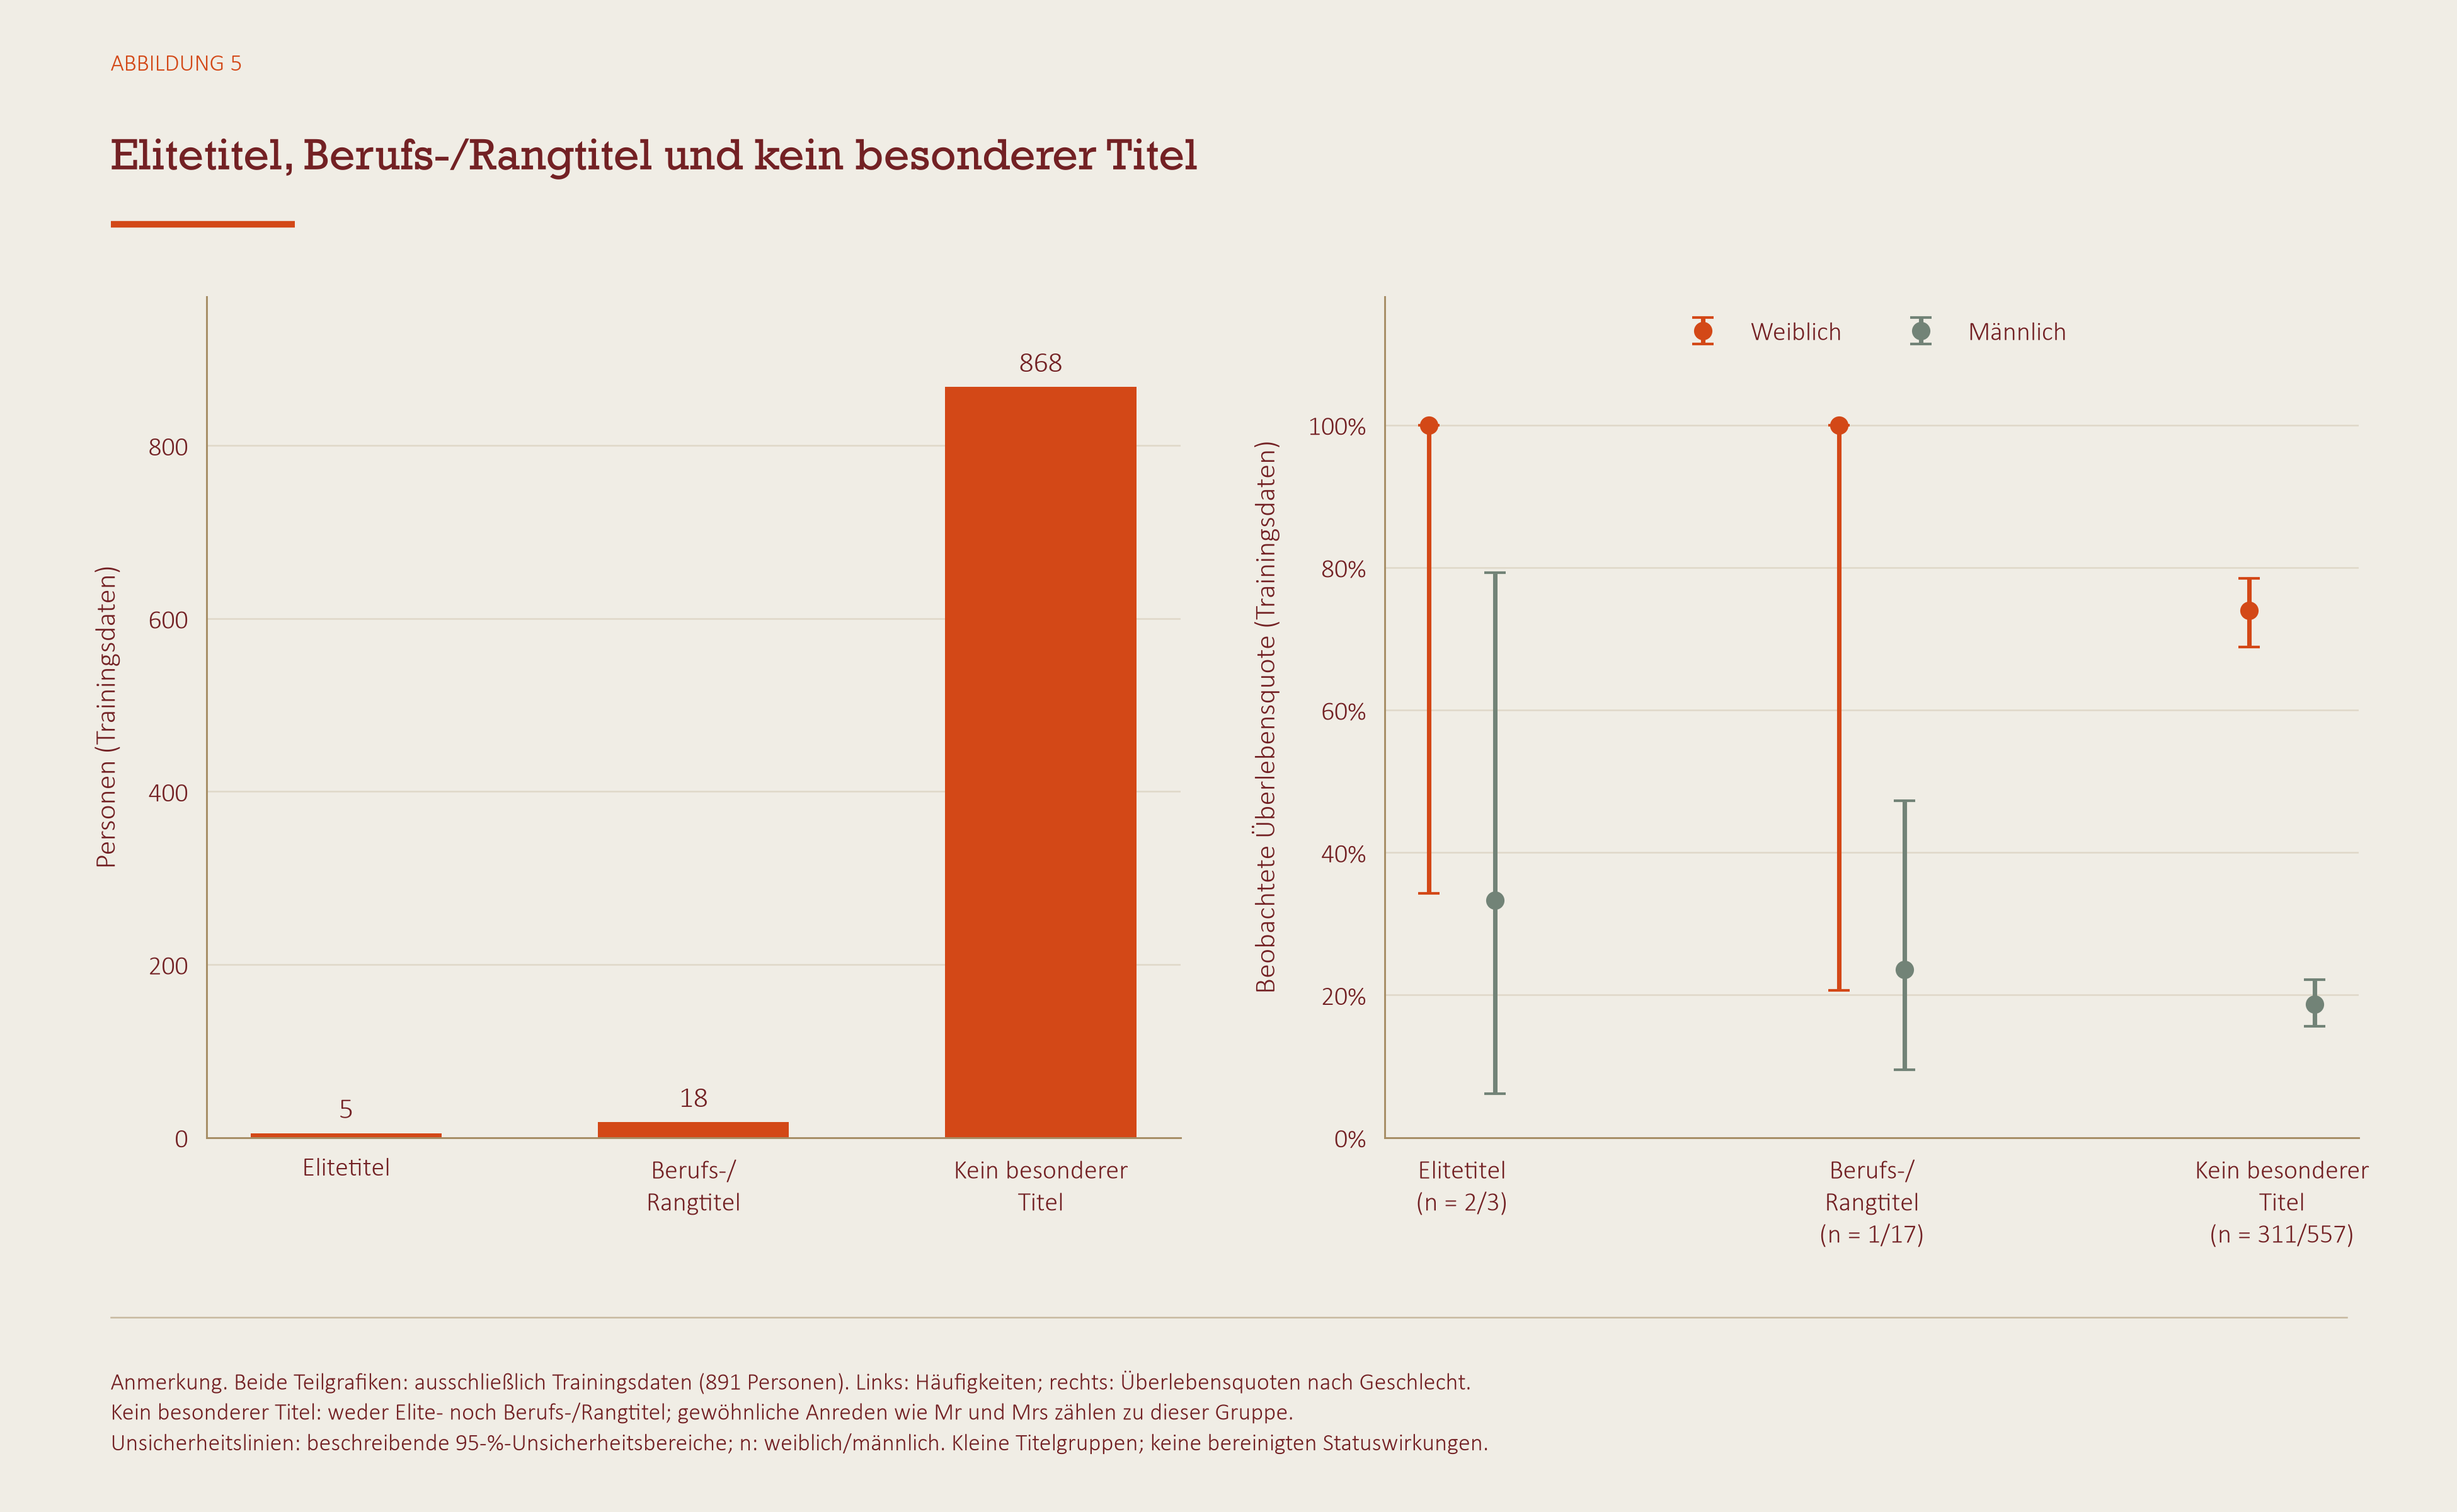

In [4]:
status_reihenfolge = ['Elitetitel', 'Berufs-/Rangtitel', 'Kein besonderer Titel']
status_gesamt, status_geschlecht, status_titelzeilen = ([], [], [])
for bereich, daten_status in [('Train', train_merkmale), ('Testdaten', test_merkmale)]:
    status = daten_status.copy()
    assert not (status.EliteStatus.eq(1) & status.HoherBerufsStatus.eq(1)).any()
    status['Statusgruppe'] = np.select([status.EliteStatus.eq(1), status.HoherBerufsStatus.eq(1)], status_reihenfolge[:2], default=status_reihenfolge[2])
    raw_status = train if bereich == 'Train' else test
    titles_by_id = raw_status.set_index('PassengerId').Name.str.extract(',[ ]*([^.]+)[.]', expand=False).str.strip()
    status['Titel'] = status.PassengerId.map(titles_by_id)
    if 'Survived' not in status:
        status['Survived'] = np.nan
    for geschlecht_getrennt in [False, True]:
        keys = ['Statusgruppe', 'Sex'] if geschlecht_getrennt else ['Statusgruppe']
        werte = status.groupby(keys).agg(Personen=('PassengerId', 'size'), Beobachtete_Zielwerte=('Survived', 'count'), Überlebende=('Survived', 'sum'), Überlebensquote=('Survived', 'mean'))
        index = pd.MultiIndex.from_product([status_reihenfolge, ['female', 'male']], names=keys) if geschlecht_getrennt else pd.Index(status_reihenfolge, name='Statusgruppe')
        werte = werte.reindex(index)
        werte[['Personen', 'Beobachtete_Zielwerte']] = werte[['Personen', 'Beobachtete_Zielwerte']].fillna(0).astype(int)
        werte.loc[werte.Beobachtete_Zielwerte.eq(0), ['Überlebende', 'Überlebensquote']] = np.nan
        nenner = werte.Beobachtete_Zielwerte.replace(0, np.nan)
        p = werte.Überlebensquote
        mitte = (p + 1.96 ** 2 / (2 * nenner)) / (1 + 1.96 ** 2 / nenner)
        breite = 1.96 * np.sqrt(p * (1 - p) / nenner + 1.96 ** 2 / (4 * nenner ** 2)) / (1 + 1.96 ** 2 / nenner)
        werte['Untergrenze'], werte['Obergrenze'] = (mitte - breite, mitte + breite)
        if geschlecht_getrennt:
            basis = werte.index.get_level_values('Sex').map(status.Sex.value_counts())
            werte['Anteil_am_Geschlecht'] = werte.Personen.to_numpy() / basis.to_numpy()
        else:
            werte['Anteil_am_Datensatz'] = werte.Personen / len(status)
        werte = werte.reset_index()
        werte.insert(0, 'Datensatz', bereich)
        (status_geschlecht if geschlecht_getrennt else status_gesamt).append(werte)
    for gruppe, titel_liste in [('Elitetitel', elite_titles), ('Berufs-/Rangtitel', high_status_professional)]:
        for titel in titel_liste:
            teil = status.loc[status.Titel.eq(titel)]
            status_titelzeilen.append({'Datensatz': bereich, 'Statusgruppe': gruppe, 'Titel': titel, 'Personen': len(teil), 'Weiblich': teil.Sex.eq('female').sum(), 'Männlich': teil.Sex.eq('male').sum(), 'Überlebende': teil.Survived.sum() if teil.Survived.notna().any() else np.nan, 'Überlebensquote': teil.Survived.mean()})
status_gesamt = pd.concat(status_gesamt, ignore_index=True)
status_geschlecht = pd.concat(status_geschlecht, ignore_index=True)
status_nach_titel = pd.DataFrame(status_titelzeilen)
for tabelle, dateiname in [(status_gesamt, 'status_gesamt'), (status_geschlecht, 'status_nach_geschlecht'), (status_nach_titel, 'status_nach_titel')]:
    display(tabelle.style.format({spalte: '{:.1%}' for spalte in tabelle.columns if spalte in ['Überlebensquote', 'Untergrenze', 'Obergrenze', 'Anteil_am_Datensatz', 'Anteil_am_Geschlecht']}, na_rep='Unbekannt / keine Beobachtung'))
fig, achsen = plt.subplots(1, 2, figsize=(13, 8))
gruppen_kurz = status_reihenfolge
positionen = np.arange(len(gruppen_kurz))
gruppen_labels = ['Elitetitel', 'Berufs-/\nRangtitel', 'Kein besonderer\nTitel']
counts = status_gesamt.loc[status_gesamt.Datensatz.eq('Train')].set_index('Statusgruppe').loc[gruppen_kurz, 'Personen']
bars = achsen[0].bar(positionen, counts, width=0.55, color=COLORS['accent1'])
achsen[0].bar_label(bars, padding=3)
achsen[0].set(xticks=positionen, xticklabels=gruppen_labels, ylabel='Personen (Trainingsdaten)', ylim=(0, counts.max() * 1.12))
for sex, versatz, farbe, text in [('female', -0.08, COLORS['accent1'], 'Weiblich'), ('male', 0.08, COLORS['accent3'], 'Männlich')]:
    g = status_geschlecht.loc[status_geschlecht.Datensatz.eq('Train') & status_geschlecht.Sex.eq(sex)]
    g = g.set_index('Statusgruppe').loc[gruppen_kurz]
    achsen[1].errorbar(positionen + versatz, g.Überlebensquote, yerr=[g.Überlebensquote - g.Untergrenze, g.Obergrenze - g.Überlebensquote], fmt='o', capsize=4, color=farbe, label=text)
anzahlen = status_geschlecht.loc[status_geschlecht.Datensatz.eq('Train')].pivot(index='Statusgruppe', columns='Sex', values='Personen')
labels = [f"{label}\n(n = {anzahlen.loc[g, 'female']}/{anzahlen.loc[g, 'male']})" for g, label in zip(gruppen_kurz, gruppen_labels)]
achsen[1].set(xticks=positionen, xticklabels=labels, ylabel='Beobachtete Überlebensquote (Trainingsdaten)', ylim=(0, 1.18))
achsen[1].set_yticks(np.arange(0, 1.01, 0.2))
achsen[1].yaxis.set_major_formatter(PercentFormatter(1))
achsen[1].legend(loc='upper center', ncol=2)
save_leaf_figure(fig, '5', 'Elitetitel, Berufs-/Rangtitel und kein besonderer Titel', 'Beide Teilgrafiken: ausschließlich Trainingsdaten (891 Personen). Links: Häufigkeiten; rechts: Überlebensquoten nach Geschlecht.\nKein besonderer Titel: weder Elite- noch Berufs-/Rangtitel; gewöhnliche Anreden wie Mr und Mrs zählen zu dieser Gruppe.\nUnsicherheitslinien: beschreibende 95-%-Unsicherheitsbereiche; n: weiblich/männlich. Kleine Titelgruppen; keine bereinigten Statuswirkungen.', ABBILDUNGEN / '05a_statusgruppen')



## Namenslänge, Ticketklasse und Geschlecht

Unterscheiden sich die Überlebensquoten nach der Länge des eingetragenen Namens? Wir betrachten vier feste Längengruppen und vergleichen zusätzlich innerhalb derselben Ticketklasse und desselben Geschlechts.

Die Namenslänge zählt alle Zeichen einschließlich Titel und Leerzeichen. Dieser Vergleich dient der Beschreibung; Namenslänge wird nicht als zusätzliches Modellmerkmal verwendet.


In [5]:
namensanalyse = train[['PassengerId', 'Name', 'Sex', 'Pclass', 'Survived']].copy()
assert len(namensanalyse) == 891 and namensanalyse.Name.notna().all()
namensanalyse['Namenslaenge'] = namensanalyse.Name.str.len()
namensgruppen = ['≤ 20', '21–30', '31–40', '≥ 41']
namensanalyse['Namenslaengengruppe'] = pd.cut(namensanalyse.Namenslaenge, bins=[0, 20, 30, 40, np.inf], labels=namensgruppen, include_lowest=True)
assert namensanalyse.Namenslaengengruppe.notna().all()

def namensquoten(daten, schluessel):
    tabelle = daten.groupby(schluessel, observed=False).Survived.agg(Personen='count', Überlebende='sum', Überlebensquote='mean')
    n = tabelle.Personen.replace(0, np.nan)
    p = tabelle.Überlebensquote
    mitte = (p + 1.96 ** 2 / (2 * n)) / (1 + 1.96 ** 2 / n)
    breite = 1.96 * np.sqrt(p * (1 - p) / n + 1.96 ** 2 / (4 * n ** 2)) / (1 + 1.96 ** 2 / n)
    tabelle['Untergrenze'] = (mitte - breite).clip(0, 1)
    tabelle['Obergrenze'] = (mitte + breite).clip(0, 1)
    tabelle.loc[tabelle.Personen.eq(0), 'Überlebende'] = np.nan
    return tabelle
namenslaenge_gesamt = namensquoten(namensanalyse, ['Namenslaengengruppe'])
namenslaenge_schichten = namensquoten(namensanalyse, ['Pclass', 'Sex', 'Namenslaengengruppe'])
assert namenslaenge_gesamt.Personen.sum() == len(train)
assert namenslaenge_schichten.Personen.sum() == len(train)
assert namenslaenge_schichten.Überlebende.sum() == train.Survived.sum()
for tabelle, dateiname in [(namenslaenge_gesamt, 'namenslaenge_gesamt'), (namenslaenge_schichten, 'namenslaenge_nach_klasse_geschlecht')]:
    display(tabelle.style.format({'Überlebensquote': '{:.1%}', 'Untergrenze': '{:.1%}', 'Obergrenze': '{:.1%}'}, na_rep='Keine Beobachtung'))
kurz = namenslaenge_schichten.loc[1, 'male', '21–30']
lang = namenslaenge_schichten.loc[1, 'male', '31–40']
gesamt_kurz = namenslaenge_gesamt.loc['≤ 20']
gesamt_lang = namenslaenge_gesamt.loc['≥ 41']
display(Markdown(f'**Beobachtung:** Insgesamt steigt die Überlebensquote von **{gesamt_kurz.Überlebensquote:.1%}** bei kurzen Namen auf **{gesamt_lang.Überlebensquote:.1%}** bei langen Namen. Innerhalb der Geschlechts- und Ticketklassen-Gruppen ist der Verlauf jedoch nicht einheitlich. Manche Gruppen sind sehr klein.'))


,Personen,Überlebende,Überlebensquote,Untergrenze,Obergrenze
Namenslaengengruppe,,,,,
≤ 20,243,56.000000,23.0%,18.2%,28.7%
21–30,426,147.000000,34.5%,30.1%,39.1%
31–40,132,67.000000,50.8%,42.3%,59.1%
≥ 41,90,72.000000,80.0%,70.6%,87.0%


**Beobachtung:** Insgesamt steigt die Überlebensquote von **23.0%** bei kurzen Namen auf **80.0%** bei langen Namen. Innerhalb der Geschlechts- und Ticketklassen-Gruppen ist der Verlauf jedoch nicht einheitlich. Manche Gruppen sind sehr klein.

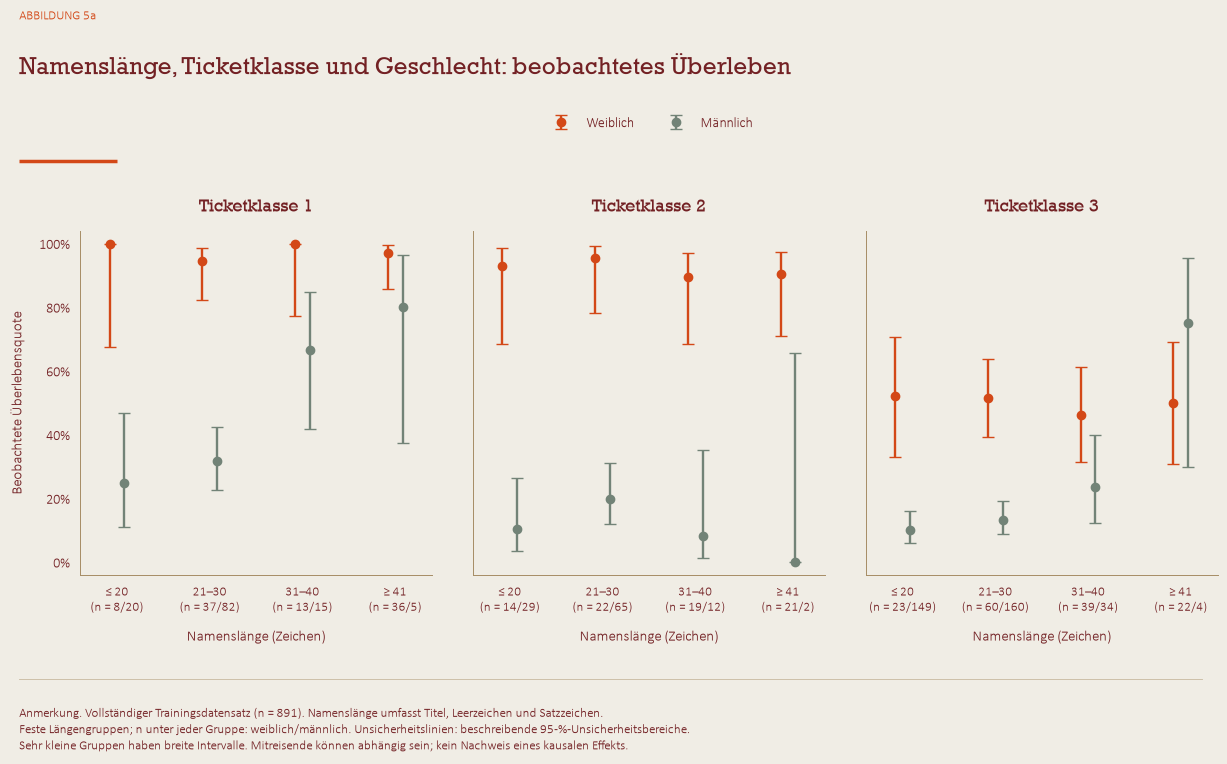

In [6]:
fig, achsen = plt.subplots(1, 3, figsize=(13, 8), sharey=True)
x = np.arange(len(namensgruppen))
for klasse, ax in enumerate(achsen, start=1):
    for sex, versatz, farbe, text in [('female', -0.08, COLORS['accent1'], 'Weiblich'), ('male', 0.08, COLORS['accent3'], 'Männlich')]:
        g = namenslaenge_schichten.xs((klasse, sex), level=['Pclass', 'Sex']).reindex(namensgruppen)
        beobachtet = g.Personen.gt(0)
        werte = g.loc[beobachtet]
        ax.errorbar(x[beobachtet] + versatz, werte.Überlebensquote, yerr=[(werte.Überlebensquote - werte.Untergrenze).clip(lower=0), (werte.Obergrenze - werte.Überlebensquote).clip(lower=0)], fmt='o', markersize=6, capsize=4, color=farbe, label=text)
    counts = namenslaenge_schichten.xs(klasse, level='Pclass').Personen.unstack('Sex')
    labels = [f"{gruppe}\n(n = {counts.loc[gruppe, 'female']}/{counts.loc[gruppe, 'male']})" for gruppe in namensgruppen]
    ax.set(title=f'Ticketklasse {klasse}', xticks=x, xticklabels=labels, xlabel='Namenslänge (Zeichen)', ylim=(-0.04, 1.04), xlim=(-0.4, 3.4))
    ax.tick_params(axis='x', labelsize=9)
    ax.set_yticks(np.arange(0, 1.01, 0.2))
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.grid(axis='y', alpha=0.18)
achsen[0].set_ylabel('Beobachtete Überlebensquote')
handles, labels = achsen[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, 0.88), ncol=2)
save_leaf_figure(fig, '5a', 'Namenslänge, Ticketklasse und Geschlecht: beobachtetes Überleben', 'Vollständiger Trainingsdatensatz (n = 891). Namenslänge umfasst Titel, Leerzeichen und Satzzeichen.\nFeste Längengruppen; n unter jeder Gruppe: weiblich/männlich. Unsicherheitslinien: beschreibende 95-%-Unsicherheitsbereiche.\nSehr kleine Gruppen haben breite Intervalle. Mitreisende können abhängig sein; kein Nachweis eines kausalen Effekts.', ABBILDUNGEN / '05b_namenslaenge_klasse_geschlecht')



## Wie bereiten wir die Angaben für Modelle vor?

Fehlende Zahlen werden später durch einen mittleren Wert aus den jeweiligen Lerndaten ergänzt. Kategorien wie der Einstiegsort werden in eine für Modelle passende Darstellung umgewandelt.

Diese Schritte lernen nur aus den Lerndaten. Die Personen, an denen wir die Vorhersage prüfen, liefern dafür keine Informationen.


## Fehlende und auffällige Angaben

- Beim Alter fehlen 177 Trainings- und 86 Testangaben. Ein ergänzter Wert ist kein tatsächlich gemessenes Alter.
- Bei Kabinen fehlen besonders viele Angaben. Unbekannt bedeutet nicht automatisch ein bestimmtes Deck.
- Zwei Einstiegsorte und ein Test-Fahrpreis fehlen.
- Nullpreise und hohe Fahrpreise bleiben erhalten, solange kein Fehler belegt ist.

Zusätzliche Hinweise kennzeichnen fehlende Angaben. Wir behalten alle Personen im Datensatz.


In [7]:
luecken = pd.DataFrame({'Train': train.isna().sum(), 'Testdaten': test.isna().sum()})
display(luecken.loc[luecken.Train + luecken['Testdaten'] > 0])
print(deutsch('Fehlende Preise:'), test.loc[test.Fare.isna(), ['PassengerId', 'Pclass']].to_dict('records'))
print(deutsch('Beobachtete Altersstreuung:'), round(analyse.Age.std(), 2))
print(deutsch('Streuung nach Median Imputation:'), round(analyse.Age.fillna(analyse.Age.median()).std(), 2))
print(deutsch('Train-Mediane (Beschreibung) des Fahrpreises je Klasse:'), analyse.groupby('Pclass').Fare.median().to_dict())
print(deutsch('Globaler Train-Median (Beschreibung) des Fahrpreises:'), analyse.Fare.median())



,Trainingsdaten,Testdaten
Age,177,86.0
Cabin,687,327.0
Embarked,2,0.0
Fare,0,1.0


Fehlende Preise: [{'PassengerId': 1044, 'Pclass': 3}]
Beobachtete Altersstreuung: 14.53
Streuung nach Ergänzung mit dem mittleren Wert: 13.02
Train-Mediane (Beschreibung) des Fahrpreises je Klasse: {1: 60.287499999999994, 2: 14.25, 3: 8.05}
Globaler Train-Median (Beschreibung) des Fahrpreises: 14.4542


## Überleben Erwachsene mit Kindern auf demselben Ticket seltener?

Wir betrachten Personen mit bekanntem Alter ab 18 Jahren. Zunächst vergleichen wir Erwachsene mit und ohne beobachtetes Kind auf demselben Ticket.

Abbildung 6 zeigt für jede Ticketklasse die beobachtete Überlebensquote auf der y-Achse, getrennt nach Geschlecht und nach beobachtetem Kind auf demselben Ticket. Unter jeder Gruppe steht `n = weiblich/männlich`; die Zahlen zählen erwachsene Personen. „Ohne Kind“ bedeutet, dass kein Kind auf demselben Ticket in der bekannten Liste beobachtet wurde. Danach vergleichen wir innerhalb derselben Geschlechts- und Ticketklassen-Gruppen. Für einen gemeinsamen Vergleich erhalten beide Gruppen dieselbe Zusammensetzung, soweit passende Vergleichspersonen vorhanden sind.

Andere Unterschiede können trotzdem bestehen. Die Auswertung belegt weder Elternschaft noch eine Ursache des Überlebens.


In [8]:
erwachsene = analyse.loc[analyse.Age >= 18].copy()
gesamt = erwachsene.groupby('ErwachsenerKinderticket').Survived.agg(Überlebende='sum', Personen='count', Überlebensquote='mean')
display(gesamt.rename(index={0: 'Kein beobachteter Kinderticket-Treffer', 1: 'Erwachsener auf Kinderticket'}))
quoten = erwachsene.groupby(['Sex', 'Pclass', 'ErwachsenerKinderticket']).Survived.agg(Überlebende='sum', Personen='count', Überlebensquote='mean')
p, n = (quoten.Überlebensquote, quoten.Personen)
nenner = 1 + 1.96 ** 2 / n
mitte = (p + 1.96 ** 2 / (2 * n)) / nenner
breite = 1.96 * np.sqrt(p * (1 - p) / n + 1.96 ** 2 / (4 * n ** 2)) / nenner
quoten['Untergrenze'] = mitte - breite
quoten['Obergrenze'] = mitte + breite
display(quoten)
raten = quoten.Überlebensquote.unstack('ErwachsenerKinderticket').dropna()
gewichte = erwachsene.groupby(['Sex', 'Pclass']).size().reindex(raten.index)
gewichte = gewichte / gewichte.sum()
standardized = raten.mul(gewichte, axis=0).sum()
standardized.name = 'Standardisierte Überlebensquote'
display(standardized.rename(index={0: 'Kein beobachteter Treffer', 1: 'Erwachsener auf Kinderticket'}).to_frame())
rohdifferenz = gesamt.loc[1, 'Überlebensquote'] - gesamt.loc[0, 'Überlebensquote']
bereinigte_differenz = standardized.loc[1] - standardized.loc[0]
print(deutsch(f'Differenz mit minus ohne Kinderticket: insgesamt {100 * rohdifferenz:+.1f} Prozentpunkte.'))
print(deutsch(f'Bei gleicher Geschlechts-/Klassenmischung: {100 * bereinigte_differenz:+.1f} Prozentpunkte.'))
print(deutsch('Das ist eine beschreibende Standardization, keine vollständige Kontrolle aller Unterschiede.'))
display(Markdown(f'**Ergebnis:** Bei gleicher Zusammensetzung nach Geschlecht und Ticketklasse beträgt der Unterschied **{100 * bereinigte_differenz:+.2f} Prozentpunkte**. Daraus ergibt sich kein allgemeiner Nachteil für Erwachsene mit Kindern auf demselben Ticket.'))


,Überlebende,Personen,Überlebensquote
ErwachsenerKinderticket,,,
Kein beobachteter Kinderticket-Treffer,189,516,0.366
Erwachsener auf Kinderticket,40,85,0.471


Überlebende  Personen  \
Sex      Pclass ErwachsenerKinderticket                          
Weiblich 1      0                                 63        64   
                1                                 12        13   
         2      0                                 42        47   
                1                                 14        15   
         3      0                                 18        44   
                1                                 10        23   
Männlich 1      0                                 34        92   
                1                                  2         5   
         2      0                                  6        72   
                1                                  0        16   
         3      0                                 26       197   
                1                                  2        13   

                                         Überlebensquote  Untergrenze  \
Sex      Pclass ErwachsenerKinderticket                                 
Weiblich 1      0                                  0.984        0.917   
                1                                  0.923        0.667   
         2      0                                  0.894        0.774   
                1                                  0.933        0.702   
         3      0                                  0.409        0.277   
                1                                  0.435        0.256   
Männlich 1      0                                  0.370        0.278   
                1                                  0.400        0.118   
         2      0                                  0.083        0.039   
                1                                  0.000        0.000   
         3      0                                  0.132        0.092   
                1                                  0.154        0.043   

                                         Obergrenze  
Sex      Pclass ErwachsenerKinderticket              
Weiblich 1      0                             0.997  
                1                             0.986  
         2      0                             0.954  
                1                             0.988  
         3      0                             0.556  
                1                             0.632  
Männlich 1      0                             0.472  
                1                             0.769  
         2      0                             0.170  
                1                             0.194  
         3      0                             0.186  
                1                             0.422

,Standardisierte Überlebensquote
ErwachsenerKinderticket,
Kein beobachteter Treffer,0.382
Erwachsener auf Kinderticket,0.381


Differenz mit minus ohne Kinderticket: insgesamt +10.4 Prozentpunkte.
Bei gleicher Geschlechts-/Klassenmischung: -0.1 Prozentpunkte.
Das ist eine beschreibende Angleichung der Gruppenzusammensetzung, keine vollständige Kontrolle aller Unterschiede.


**Ergebnis:** Bei gleicher Zusammensetzung nach Geschlecht und Ticketklasse beträgt der Unterschied **-0.05 Prozentpunkte**. Daraus ergibt sich kein allgemeiner Nachteil für Erwachsene mit Kindern auf demselben Ticket.

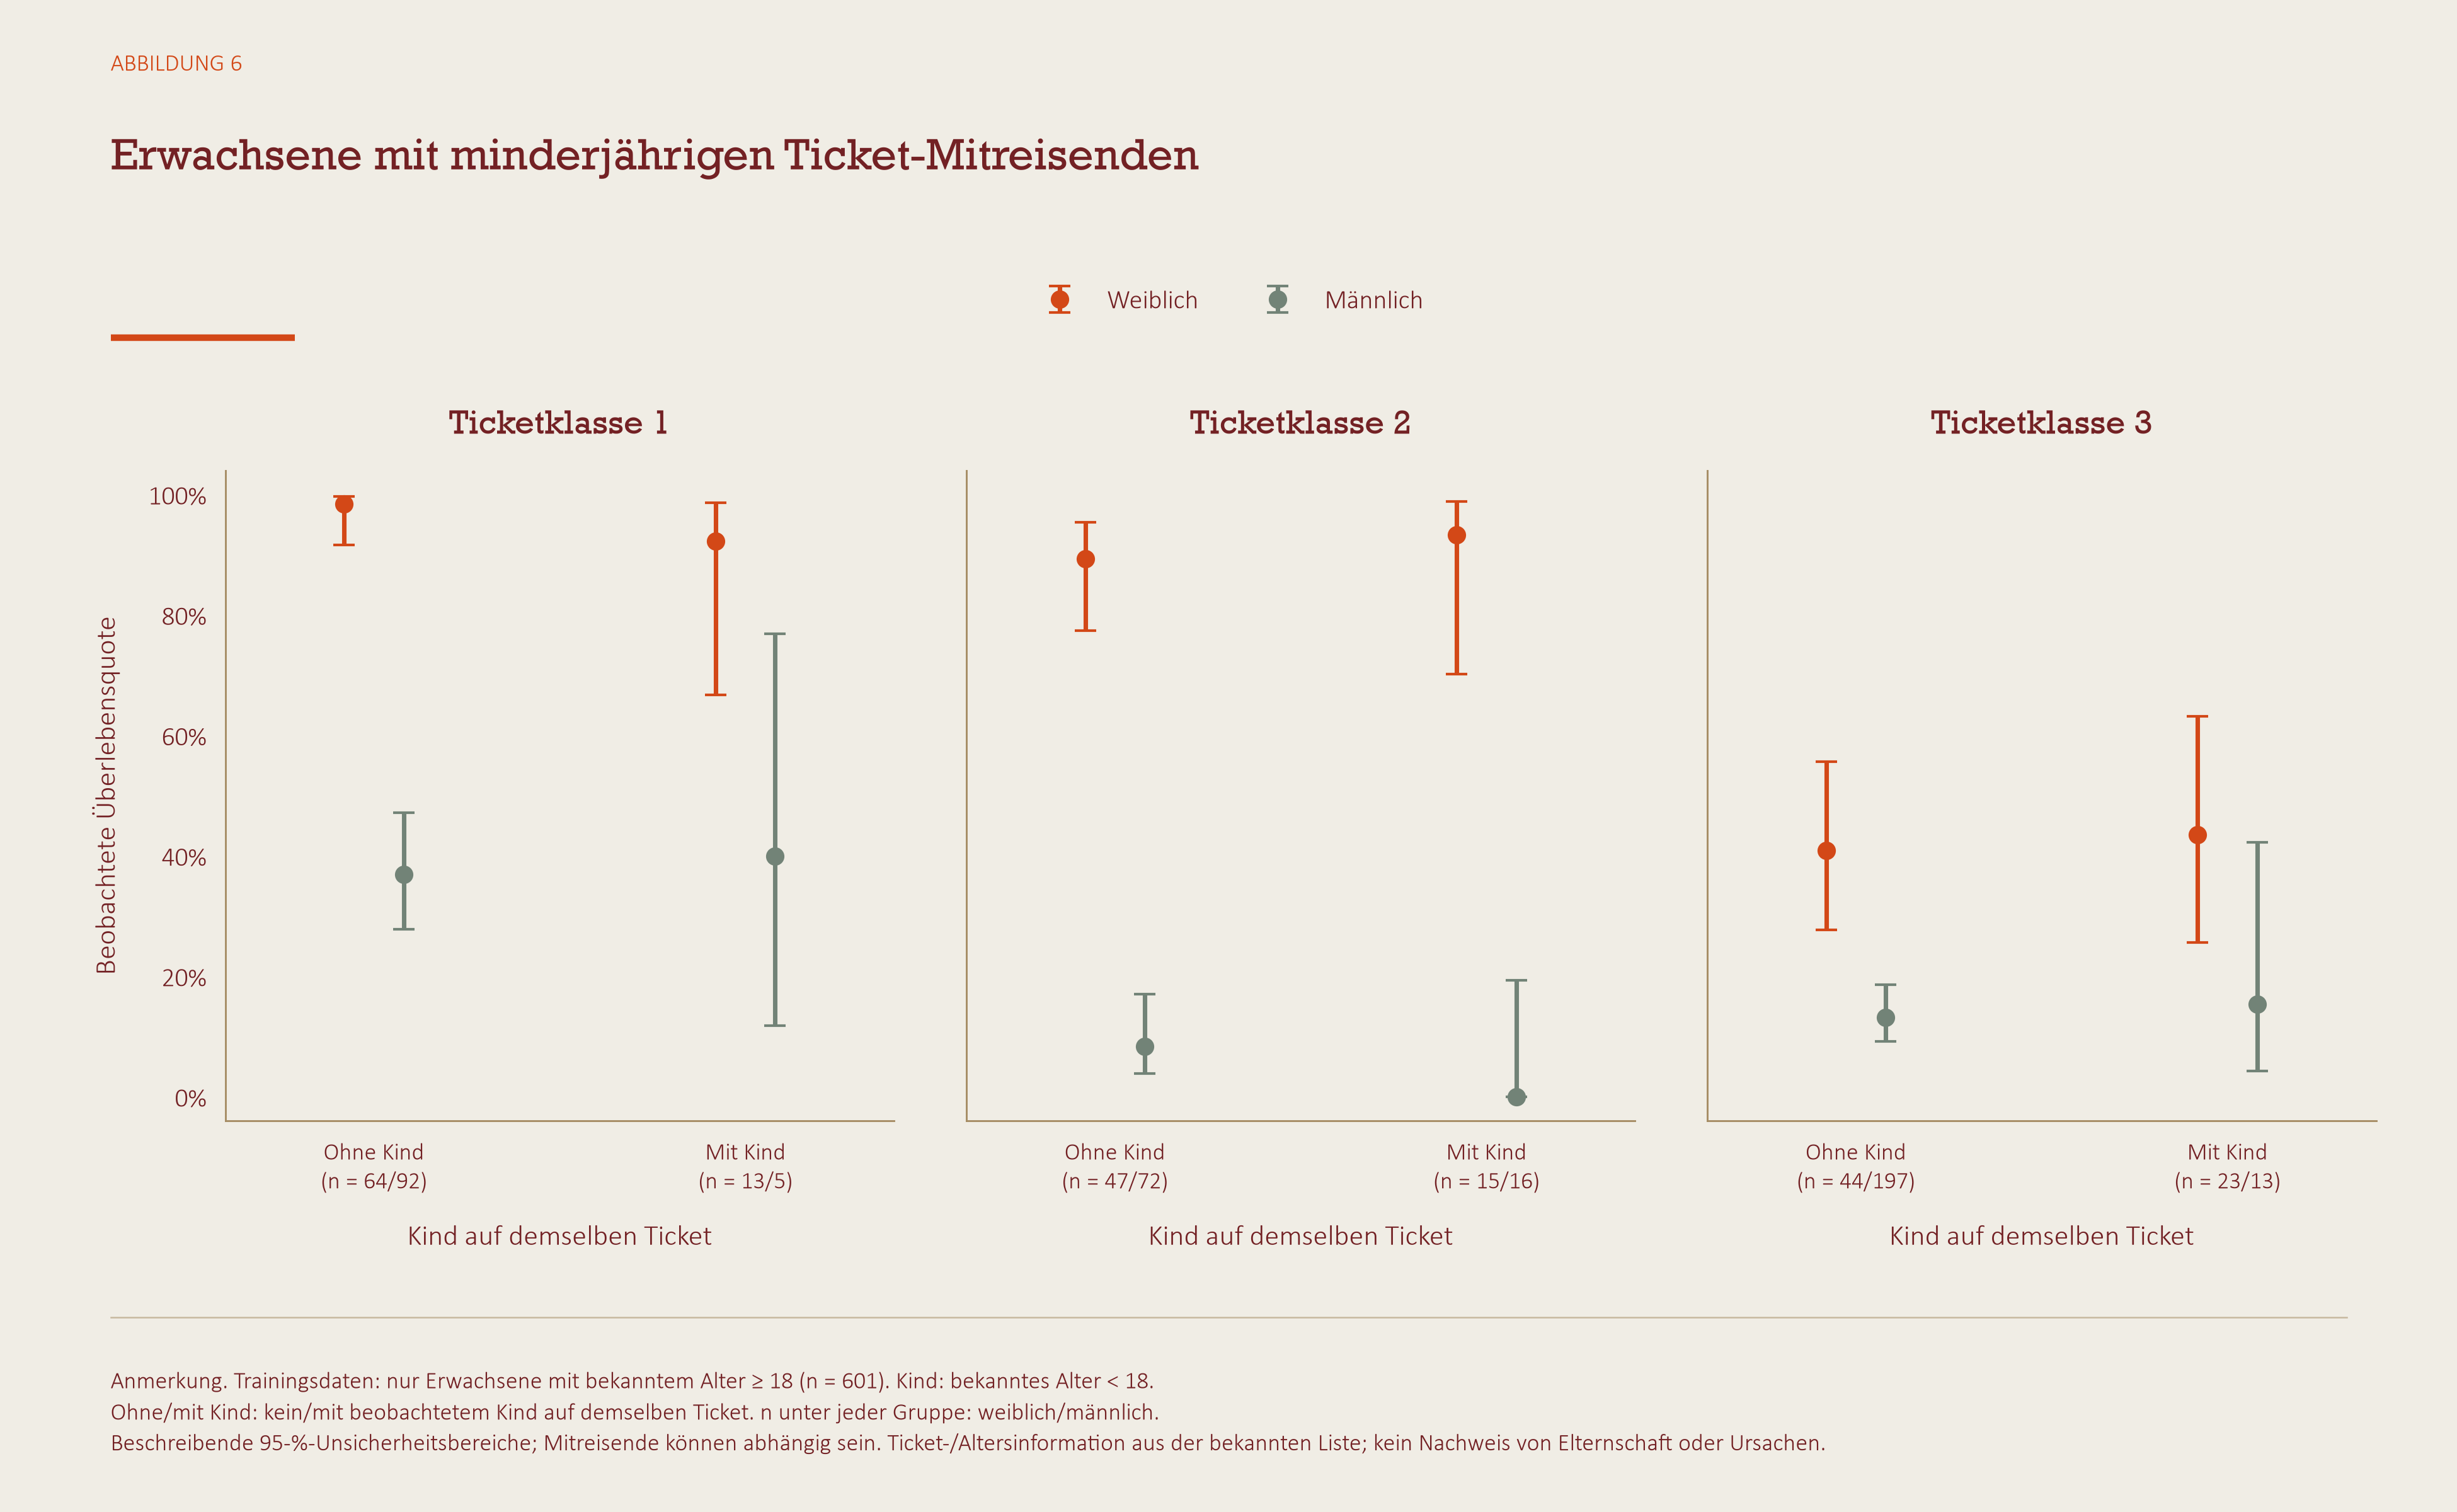

In [9]:
fig, achsen = plt.subplots(1, 3, figsize=(13, 8), sharey=True)
kinderticket_gruppen = [0, 1]
x = np.arange(len(kinderticket_gruppen))
for klasse, ax in enumerate(achsen, start=1):
    for sex, versatz, farbe, text in [('female', -0.08, COLORS['accent1'], 'Weiblich'), ('male', 0.08, COLORS['accent3'], 'Männlich')]:
        g = quoten.xs((sex, klasse), level=['Sex', 'Pclass']).reindex(kinderticket_gruppen)
        beobachtet = g.Personen.gt(0)
        werte = g.loc[beobachtet]
        ax.errorbar(x[beobachtet] + versatz, werte.Überlebensquote, yerr=[(werte.Überlebensquote - werte.Untergrenze).clip(lower=0), (werte.Obergrenze - werte.Überlebensquote).clip(lower=0)], fmt='o', markersize=6, capsize=4, color=farbe, label=text)
    counts = quoten.xs(klasse, level='Pclass').Personen.unstack('Sex').reindex(index=kinderticket_gruppen, columns=['female', 'male']).fillna(0).astype(int)
    labels = [f"{text}\n(n = {counts.loc[flag, 'female']}/{counts.loc[flag, 'male']})" for flag, text in [(0, 'Ohne Kind'), (1, 'Mit Kind')]]
    ax.set(title=f'Ticketklasse {klasse}', xticks=x, xticklabels=labels, xlabel='Kind auf demselben Ticket', ylim=(-0.04, 1.04), xlim=(-0.4, 1.4))
    ax.tick_params(axis='x', labelsize=9)
    ax.set_yticks(np.arange(0, 1.01, 0.2))
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.grid(axis='y', alpha=0.18)
achsen[0].set_ylabel('Beobachtete Überlebensquote')
handles, labels = achsen[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, 0.88), ncol=2)
save_leaf_figure(fig, '6', 'Erwachsene mit minderjährigen Ticket-Mitreisenden', f'Trainingsdaten: nur Erwachsene mit bekanntem Alter ≥ 18 (n = {len(erwachsene)}). Kind: bekanntes Alter < 18.\nOhne/mit Kind: kein/mit beobachtetem Kind auf demselben Ticket. n unter jeder Gruppe: weiblich/männlich.\nBeschreibende 95-%-Unsicherheitsbereiche; Mitreisende können abhängig sein. Ticket-/Altersinformation aus der bekannten Liste; kein Nachweis von Elternschaft oder Ursachen.', ABBILDUNGEN / '06_kinderticket_survival')



## Ist die Überlebensquote im hinteren Schiffsteil höher?

Wir verwenden die oben beschriebene vereinfachte Kabinenzuordnung. Unbekannte Angaben werden keiner Position zugeordnet.

Neben dem Gesamtvergleich betrachten wir Personen mit gleichem Deck, Geschlecht und gleicher Ticketklasse. Nur Gruppen mit bekannten Angaben für beide Positionen können direkt verglichen werden. Kleine Gruppen und die ungenaue Lagezuordnung begrenzen die Aussage.


In [10]:
kabinen_haeufigkeit = analyse.groupby('Kabinenlage').Survived.agg(Überlebende='sum', Personen='count', Überlebensquote='mean')
display(kabinen_haeufigkeit)
zugeordnet = analyse.loc[analyse.Kabinenposition.isin(['Front', 'Heck'])]
kabinen_gesamt = zugeordnet.groupby('Kabinenposition').Survived.agg(Überlebende='sum', Personen='count', Überlebensquote='mean')
display(kabinen_gesamt)
kabinen_deck = zugeordnet.groupby(['Kabinendeck', 'Kabinenposition']).Survived.agg(Überlebende='sum', Personen='count', Überlebensquote='mean')
kabinen_schichten = zugeordnet.groupby(['Kabinendeck', 'Sex', 'Pclass', 'Kabinenposition']).Survived.agg(Überlebende='sum', Personen='count', Überlebensquote='mean')
display(kabinen_schichten)
raten_kabine = kabinen_schichten.Überlebensquote.unstack('Kabinenposition').dropna()
gewichte_kabine = zugeordnet.groupby(['Kabinendeck', 'Sex', 'Pclass']).size().reindex(raten_kabine.index)
gemeinsame_personen = int(gewichte_kabine.sum())
gewichte_kabine = gewichte_kabine / gewichte_kabine.sum()
kabinen_standardisiert = raten_kabine.mul(gewichte_kabine, axis=0).sum()
kabinen_standardisiert.name = 'Standardisierte Überlebensquote'
display(kabinen_standardisiert.to_frame())
print(deutsch(f'Eindeutige Position: {len(zugeordnet)} von {len(analyse)} Trainingspersonen.'))
print(deutsch(f'Standardization: {len(raten_kabine)} gemeinsame Deck-/Geschlechts-/Klassen-Schichten, {gemeinsame_personen} von {len(zugeordnet)} zugeordneten Personen.'))
print(deutsch(f"Heck minus Front, insgesamt: {100 * (kabinen_gesamt.loc['Heck', 'Überlebensquote'] - kabinen_gesamt.loc['Front', 'Überlebensquote']):+.1f} Prozentpunkte."))
print(deutsch(f"Heck minus Front, standardized: {100 * (kabinen_standardisiert['Heck'] - kabinen_standardisiert['Front']):+.1f} Prozentpunkte."))
print(deutsch('Keine kausale Aussage und kein unabhängiger Test; die Kabinenpositionen bleiben unverändert.'))
display(Markdown('**Ergebnis der Hypothesenprüfung:** ' + ('Die gesamte Heckquote ist höher. ' if kabinen_gesamt.loc['Heck', 'Überlebensquote'] > kabinen_gesamt.loc['Front', 'Überlebensquote'] else 'Die vermutete höhere Heckquote zeigt sich im Gesamtvergleich nicht. ') + f"Die standardized Quoten betragen Front **{kabinen_standardisiert['Front']:.1%}**, Heck **{kabinen_standardisiert['Heck']:.1%}**. " + 'Sie betreffen nur die gemeinsamen Schichten. Kleine Gruppen erlauben keine allgemeine historische Regel. Ein Feature kann trotzdem beim Vorhersagen helfen, ohne die vermutete Richtung zu bestätigen.'))



,Überlebende,Personen,Überlebensquote
Kabinenlage,,,
A-Front,7,15,0.467
B-Front,20,26,0.769
B-Heck,12,17,0.706
B-Unklar,3,4,0.750
C-Front,19,31,0.613
C-Heck,16,28,0.571
D-Front,22,29,0.759
D-Heck,1,1,1.000
D-Unklar,2,3,0.667


,Überlebende,Personen,Überlebensquote
Kabinenposition,,,
Front,85,122,0.697
Heck,46,74,0.622


Überlebende  Personen  \
Kabinendeck Sex      Pclass Kabinenposition                          
A           Weiblich 1      Front                      1         1   
            Männlich 1      Front                      6        14   
B           Weiblich 1      Front                     15        15   
                            Heck                       9         9   
            Männlich 1      Front                      5        11   
                            Heck                       3         8   
C           Weiblich 1      Front                     13        16   
                            Heck                      11        11   
            Männlich 1      Front                      6        15   
                            Heck                       5        17   
D           Weiblich 1      Front                     16        16   
            Männlich 1      Front                      6        13   
                     2      Heck                       1         1   
E           Weiblich 1      Front                      8         8   
                            Heck                       2         2   
                     2      Heck                       3         4   
                     3      Heck                       1         1   
            Männlich 1      Front                      8        12   
                            Heck                       0         3   
                     3      Front                      1         1   
                            Heck                       1         1   
F           Weiblich 2      Heck                       4         4   
                     3      Heck                       1         1   
            Männlich 2      Heck                       3         4   
                     3      Heck                       0         4   
G           Weiblich 3      Heck                       2         4   

                                             Überlebensquote  
Kabinendeck Sex      Pclass Kabinenposition                   
A           Weiblich 1      Front                      1.000  
            Männlich 1      Front                      0.429  
B           Weiblich 1      Front                      1.000  
                            Heck                       1.000  
            Männlich 1      Front                      0.455  
                            Heck                       0.375  
C           Weiblich 1      Front                      0.812  
                            Heck                       1.000  
            Männlich 1      Front                      0.400  
                            Heck                       0.294  
D           Weiblich 1      Front                      1.000  
            Männlich 1      Front                      0.462  
                     2      Heck                       1.000  
E           Weiblich 1      Front                      1.000  
                            Heck                       1.000  
                     2      Heck                       0.750  
                     3      Heck                       1.000  
            Männlich 1      Front                      0.667  
                            Heck                       0.000  
                     3      Front                      1.000  
                            Heck                       1.000  
F           Weiblich 2      Heck                       1.000  
                     3      Heck                       1.000  
            Männlich 2      Heck                       0.750  
                     3      Heck                       0.000  
G           Weiblich 3      Heck                       0.500

,Standardisierte Überlebensquote
Kabinenposition,
Front,0.693
Heck,0.617


Eindeutige Position: 196 von 891 Trainingspersonen.
Angleichung der Gruppenzusammensetzung: 7 gemeinsame Deck-/Geschlechts-/Klassen-Schichten, 129 von 196 zugeordneten Personen.
Heck minus Front, insgesamt: -7.5 Prozentpunkte.
Heck minus Front, bei gleicher Gruppenzusammensetzung: -7.6 Prozentpunkte.
Keine kausale Aussage und kein unabhängiger Test; die Kabinenpositionen bleiben unverändert.


**Ergebnis der Hypothesenprüfung:** Die vermutete höhere Heckquote zeigt sich im Gesamtvergleich nicht. Die bei gleicher Gruppenzusammensetzung Quoten betragen Front **69.3%**, Heck **61.7%**. Sie betreffen nur die gemeinsamen Schichten. Kleine Gruppen erlauben keine allgemeine historische Regel. Ein Merkmal kann trotzdem beim Vorhersagen helfen, ohne die vermutete Richtung zu bestätigen.

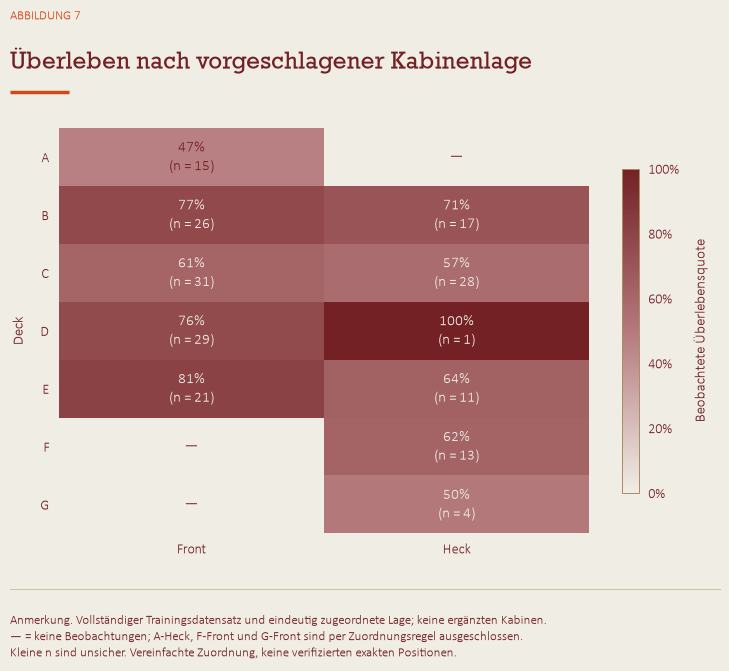

In [11]:
decks = list('ABCDEFG')
positionen = ['Front', 'Heck']
quoten_deck = kabinen_deck.Überlebensquote.unstack('Kabinenposition').reindex(index=decks, columns=positionen)
anzahl_deck = kabinen_deck.Personen.unstack('Kabinenposition').reindex(index=decks, columns=positionen)
fig, ax = plt.subplots(figsize=(7.8, 7.0))
karte = ax.imshow(quoten_deck.to_numpy(), cmap=LEAF_CMAP, vmin=0, vmax=1, aspect='auto')
for i, deck in enumerate(decks):
    for j, position in enumerate(positionen):
        rate, n = (quoten_deck.loc[deck, position], anzahl_deck.loc[deck, position])
        text = '—' if pd.isna(rate) else f'{rate:.0%}\n(n = {int(n)})'
        ax.text(j, i, text, ha='center', va='center', color=heatmap_text_color(rate) if pd.notna(rate) else COLORS['dk2'], fontsize=11)
ax.set(xticks=[0, 1], xticklabels=positionen, yticks=np.arange(7), yticklabels=decks, ylabel='Deck')
for spine in ax.spines.values():
    spine.set_visible(False)
fig.colorbar(karte, ax=ax, format=PercentFormatter(1), label='Beobachtete Überlebensquote', shrink=0.8)
save_leaf_figure(fig, '7', 'Überleben nach vorgeschlagener Kabinenlage', 'Vollständiger Trainingsdatensatz und eindeutig zugeordnete Lage; keine ergänzten Kabinen.\n— = keine Beobachtungen; A-Heck, F-Front und G-Front sind per Zuordnungsregel ausgeschlossen.\nKleine n sind unsicher. Nutzergrenzen nach Deckplänen, keine verifizierten exakten Positionen.', ABBILDUNGEN / '07_kabinenlage_survival')



Weiter zu [Notebook 3: Modelle vergleichen](03_Modellvergleich.ipynb). Dort prüfen wir, welche Gruppen von Merkmalen tatsächlich bei der Vorhersage helfen.


## Quellen

Daten: `train.csv` und `test.csv`. Aufgabenstellung: `Task_description.pdf`. Fachliche Grundlage: Lisa Grobelscheg, *Skriptum LV DSM, ITW 26/27* (`Skriptum.pdf`).

KI-Unterstützung wurde für Code, Abbildungen und Erklärungen verwendet.

Anregungen: [Titanic-Beispiel auf Kaggle](https://www.kaggle.com/code/nikitakudriashov/top-1-titanic-solution) und [Deckpläne von Encyclopedia Titanica](https://www.encyclopedia-titanica.org/titanic-deckplans/). Die vereinfachte Kabineneinteilung ist eine eigene Annahme.
